In [1]:
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.stats import fisher_exact, mannwhitneyu, wilcoxon

HERE = Path.cwd()
DATA = Path(os.environ.get("A2_DATA", HERE.parents[1] / "__data__" / "A2"))
OUT = HERE / "results"
OUT.mkdir(exist_ok=True)
assert DATA.exists(), f"no experiment data at {DATA}"

BG = "#f7f4f0"

sns.set_theme(style="ticks")
mpl.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 400,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.03,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "savefig.facecolor": BG,
        "font.family": "serif",
        "font.serif": ["Times New Roman", "STIX Two Text", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 8,
        "axes.labelsize": 8.5,
        "axes.titlesize": 9.5,
        "axes.labelcolor": "#444444",
        "axes.edgecolor": "#cccccc",
        "axes.linewidth": 0.8,
        "text.color": "#1a1a1a",
        "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5,
        "xtick.color": "#444444",
        "ytick.color": "#444444",
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.major.size": 2.5,
        "ytick.major.size": 2.5,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#dddddd",
        "grid.linewidth": 0.6,
        "grid.linestyle": "--",
        "legend.fontsize": 7.5,
        "legend.frameon": True,
        "legend.facecolor": "white",
        "legend.edgecolor": "#cccccc",
        "legend.framealpha": 1.0,
        "legend.labelcolor": "#1a1a1a",
        "legend.handlelength": 1.8,
        "legend.labelspacing": 0.35,
        "lines.linewidth": 1.2,
    }
)

ALL_CONFIGS = ["mut", "xmut", "xrand", "xunit", "random"]
CONFIGS = [c for c in ALL_CONFIGS if (DATA / c).is_dir()]
LABELS = {
    "mut": "Mutation only",
    "xmut": "Crossover + mutation",
    "xrand": "Headless chicken",
    "xunit": "Unit crossover + mutation",
    "random": "Random search",
}
COLORS = {
    "mut": "#2255cc",
    "xmut": "#cc4422",
    "xrand": "#d99a1e",
    "xunit": "#2a9d6f",
    "random": "#5b5b5b",
}
EA_CONFIGS = [c for c in CONFIGS if c != "random"]
COL_W, PAGE_W = 3.35, 7.0
EARLY_FRACTION = 0.2  # exploratory early-budget comparison
SESOI = 0.21  # smallest effect of interest: |A12 - 0.5| >= 0.21 (A12 >= 0.71 or <= 0.29)


def panel_title(ax, text):
    """Italic serif panel title."""
    ax.set_title(text, color="#1a1a1a", fontfamily="serif", fontstyle="italic", pad=6)


CONFIGS

['mut', 'xmut', 'xrand', 'random']

In [2]:
frames = []
for config in CONFIGS:
    for f in sorted((DATA / config).glob("seed_*/generations.csv")):
        run = pd.read_csv(f)
        run["config"] = config
        run["seed"] = int(f.parent.name.split("_")[1])
        frames.append(run)
df = pd.concat(frames, ignore_index=True)

last = df.groupby(["config", "seed"]).tail(1)
assert last["evals"].nunique() == 1, "runs have unequal evaluation budgets"
BUDGET = int(last["evals"].iloc[0])
last.groupby("config").agg(
    runs=("seed", "size"), last_gen=("gen", "first"), evals=("evals", "first")
).reindex(CONFIGS)

,runs,last_gen,evals
config,,,
mut,15,300,9030
xmut,15,300,9030
xrand,10,300,9030
random,10,300,9030


In [3]:
final = last.set_index(["config", "seed"])["best_so_far"]
summary = (
    final.groupby("config")
    .agg(
        n="size",
        mean="mean",
        std="std",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        min="min",
        max="max",
    )
    .reindex(CONFIGS)
)
summary.to_csv(OUT / "final_best.csv")
summary.round(3)

,n,mean,std,median,q1,q3,min,max
config,,,,,,,,
mut,15,0.618,0.593,0.457,0.035,1.014,0.002,1.912
xmut,15,0.473,0.478,0.391,0.007,0.903,0.001,1.179
xrand,10,2.273,0.205,2.315,2.125,2.435,1.881,2.539
random,10,2.418,0.129,2.459,2.306,2.505,2.209,2.590


In [4]:
def a12(x, y):
    """Vargha-Delaney A12 = P(X < Y) + 0.5 P(X = Y); > 0.5 means X is better (lower)."""
    x = np.asarray(x, dtype=float)[:, None]
    y = np.asarray(y, dtype=float)[None, :]
    return float(((x < y).sum() + 0.5 * (x == y).sum()) / (x.size * y.size))


def a12_ci(x, y, n_boot=10_000, seed=0):
    """Percentile bootstrap 95% CI of A12 (resampling both groups)."""
    rng = np.random.default_rng(seed)
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    stats = [
        a12(rng.choice(x, x.size), rng.choice(y, y.size)) for _ in range(n_boot)
    ]
    return tuple(np.percentile(stats, [2.5, 97.5]))


def holm(p):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p, dtype=float)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(np.argsort(p, kind="stable")):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adjusted[i] = running
    return adjusted


assert a12([1, 2, 3], [4, 5, 6]) == 1.0 and a12([1], [1, 2]) == 0.75
assert np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])


def best_at(config, evals=None):
    """Best-so-far per seed at the end, or at the first logged point >= evals."""
    runs = df[df["config"] == config]
    if evals is not None:
        runs = runs[runs["evals"] >= evals].groupby("seed").head(1)
    else:
        runs = runs.groupby("seed").tail(1)
    return runs.sort_values("seed").set_index("seed")["best_so_far"]


def compare(x, y, evals=None):
    """Two-sided Mann-Whitney U + A12 (CI) + paired Wilcoxon on shared seeds."""
    sx, sy = best_at(x, evals), best_at(y, evals)
    shared = sx.index.intersection(sy.index)
    paired = wilcoxon(sx[shared], sy[shared]) if len(shared) >= 5 else None
    lo, hi = a12_ci(sx, sy)
    effect = a12(sx, sy)
    return {
        "X": x,
        "Y": y,
        "n_X": len(sx),
        "n_Y": len(sy),
        "median_X": sx.median(),
        "median_Y": sy.median(),
        "U": mannwhitneyu(sx, sy, alternative="two-sided").statistic,
        "p_mwu": mannwhitneyu(sx, sy, alternative="two-sided").pvalue,
        "A12 P(X<Y)": effect,
        "A12 CI low": lo,
        "A12 CI high": hi,
        "large effect": abs(effect - 0.5) >= SESOI,
        "n_paired": len(shared),
        "p_wilcoxon_paired": paired.pvalue if paired is not None else np.nan,
    }


# Confirmatory family (Holm-corrected): H1, H2 and H3 (each EA vs random).
FAMILY = [("H1", "xmut", "mut"), ("H2", "xmut", "xrand")]
FAMILY += [("H3", c, "random") for c in ("mut", "xmut", "xrand")]
FAMILY = [f for f in FAMILY if f[1] in CONFIGS and f[2] in CONFIGS]
tests = pd.DataFrame([{"hypothesis": h, **compare(x, y)} for h, x, y in FAMILY])
tests["p_holm"] = holm(tests["p_mwu"])
tests.to_csv(OUT / "tests.csv", index=False)
tests.round(4)

,hypothesis,X,Y,n_X,n_Y,median_X,median_Y,U,p_mwu,A12 P(X<Y),A12 CI low,A12 CI high,large effect,n_paired,p_wilcoxon_paired,p_holm
0,H1,xmut,mut,15,15,0.3915,0.4569,91.0,0.3837,0.5956,0.3778,0.7911,False,15,0.5245,0.3837
1,H2,xmut,xrand,15,10,0.3915,2.3153,0.0,0.0000,1.0000,1.0000,1.0000,True,10,0.0020,0.0002
2,H3,mut,random,15,10,0.4569,2.4585,0.0,0.0000,1.0000,1.0000,1.0000,True,10,0.0020,0.0002
3,H3,xmut,random,15,10,0.3915,2.4585,0.0,0.0000,1.0000,1.0000,1.0000,True,10,0.0020,0.0002
4,H3,xrand,random,10,10,2.3153,2.4585,27.0,0.0890,0.7300,0.4900,0.9200,True,10,0.2324,0.1779


In [5]:
# Exploratory (NOT in the Holm family): early budget, and the optional xunit arm.
early_evals = int(EARLY_FRACTION * BUDGET)
rows = [
    {"comparison": f"{h} at {early_evals} evals", **compare(x, y, early_evals)}
    for h, x, y in FAMILY
    if h in {"H1", "H2"}
]
if "xunit" in CONFIGS:
    rows += [
        {"comparison": f"xunit vs {y} (final)", **compare("xunit", y)}
        for y in ("xmut", "mut")
    ]
exploratory = pd.DataFrame(rows)
exploratory.to_csv(OUT / "tests_exploratory.csv", index=False)
exploratory.round(4)

,comparison,X,Y,n_X,n_Y,median_X,median_Y,U,p_mwu,A12 P(X<Y),A12 CI low,A12 CI high,large effect,n_paired,p_wilcoxon_paired
0,H1 at 1806 evals,xmut,mut,15,15,1.0053,1.3434,78.0,0.1585,0.6533,0.4444,0.8444,False,15,0.2293
1,H2 at 1806 evals,xmut,xrand,15,10,1.0053,2.5272,0.0,0.0000,1.0000,1.0000,1.0000,True,10,0.0020


In [6]:
# Exploratory: how many runs actually reach the target, and how fast.
SUCCESS_M = 0.1  # "reached the target": final planar distance <= 10 cm
rows = []
for config in CONFIGS:
    runs = df[df["config"] == config]
    final_c = runs.groupby("seed")["best_so_far"].last()
    hit = runs[runs["best_so_far"] <= SUCCESS_M].groupby("seed")["evals"].min()
    rows.append(
        {
            "config": config,
            "runs": len(final_c),
            "reached target": int((final_c <= SUCCESS_M).sum()),
            "success rate": float((final_c <= SUCCESS_M).mean()),
            "median evals to reach (successful runs)": hit.median() if len(hit) else np.nan,
        }
    )
success = pd.DataFrame(rows)
success.to_csv(OUT / "success.csv", index=False)
if {"mut", "xmut"} <= set(CONFIGS):
    s = success.set_index("config")
    table = [
        [s.loc[c, "reached target"], s.loc[c, "runs"] - s.loc[c, "reached target"]]
        for c in ("xmut", "mut")
    ]
    print(f"Fisher exact test, xmut vs mut success: p = {fisher_exact(table).pvalue:.3f}")
success.round(3)

Fisher exact test, xmut vs mut success: p = 0.710


,config,runs,reached target,success rate,median evals to reach (successful runs)
0,mut,15,5,0.333,5820.0
1,xmut,15,7,0.467,3870.0
2,xrand,10,0,0.000,NaN
3,random,10,0,0.000,NaN


In [7]:
# Plateau check (stopping criterion): the mean best-so-far curve improves by
# < 1% over the last 20% of the evaluation budget, for EVERY configuration.
rows = []
for config in CONFIGS:
    curve = df[df["config"] == config].groupby("evals")["best_so_far"].mean()
    at_80 = curve[curve.index >= 0.8 * BUDGET].iloc[0]
    end = curve.iloc[-1]
    rows.append(
        {
            "config": config,
            "mean best at 80%": at_80,
            "mean best at end": end,
            "relative improvement": (at_80 - end) / at_80,
            "plateau": (at_80 - end) / at_80 < 0.01,
        }
    )
plateau = pd.DataFrame(rows)
plateau.to_csv(OUT / "plateau.csv", index=False)
plateau.round(4)

,config,mean best at 80%,mean best at end,relative improvement,plateau
0,mut,0.6663,0.6176,0.0730,False
1,xmut,0.5034,0.4727,0.0610,False
2,xrand,2.3710,2.2734,0.0412,False
3,random,2.4332,2.4175,0.0064,True


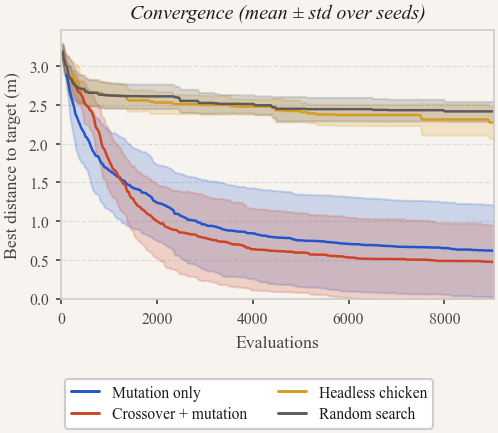

In [8]:
fig, ax = plt.subplots(figsize=(COL_W, 2.9))
for config in CONFIGS:
    sns.lineplot(
        data=df[df["config"] == config],
        x="evals",
        y="best_so_far",
        color=COLORS[config],
        errorbar="sd",
        legend=False,
        ax=ax,
    )
panel_title(ax, "Convergence (mean ± std over seeds)")
ax.set_xlabel("Evaluations")
ax.set_ylabel("Best distance to target (m)")
ax.set_xlim(0, BUDGET)
ax.set_ylim(bottom=0)
handles = [Line2D([], [], color=COLORS[c], lw=1.4, label=LABELS[c]) for c in CONFIGS]
fig.tight_layout(pad=0.4, rect=(0, 0.17, 1, 1))
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.savefig(OUT / "fig1_convergence.png")
fig.savefig(OUT / "fig1_convergence.pdf")
plt.show()

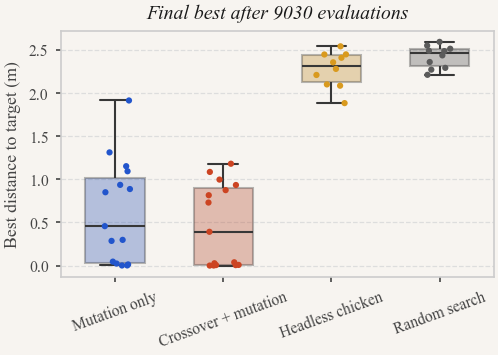

In [9]:
fig, ax = plt.subplots(figsize=(COL_W, 2.4))
data = last.assign(label=last["config"].map(LABELS))
order = [LABELS[c] for c in CONFIGS]
palette = {LABELS[c]: COLORS[c] for c in CONFIGS}
sns.boxplot(
    data=data,
    x="label",
    y="best_so_far",
    hue="label",
    order=order,
    palette=palette,
    width=0.55,
    fliersize=0,
    boxprops={"alpha": 0.35},
    legend=False,
    ax=ax,
)
sns.stripplot(
    data=data,
    x="label",
    y="best_so_far",
    hue="label",
    order=order,
    palette=palette,
    size=3,
    jitter=0.15,
    legend=False,
    ax=ax,
)
panel_title(ax, f"Final best after {BUDGET} evaluations")
ax.set_xlabel("")
ax.set_ylabel("Best distance to target (m)")
ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout(pad=0.4)
fig.savefig(OUT / "fig2_final_best.png")
fig.savefig(OUT / "fig2_final_best.pdf")
plt.show()

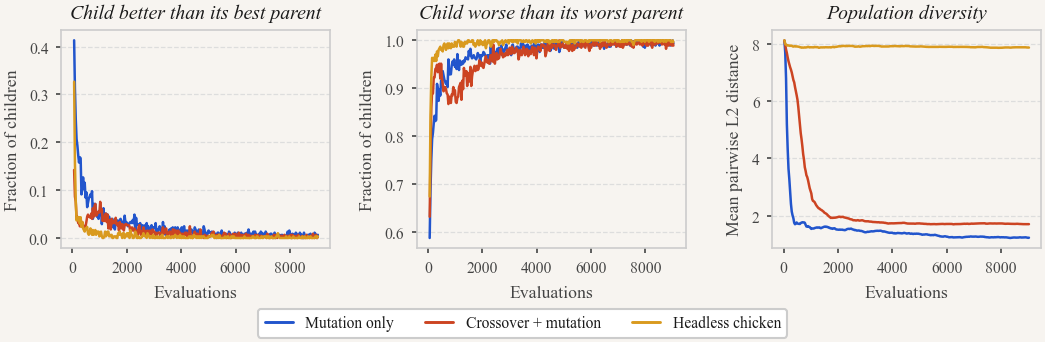

In [10]:
# Why does (or doesn't) crossover help? Offspring quality and population diversity.
ea = df[df["config"].isin(EA_CONFIGS)]
panels = [
    ("child_better_than_best_parent", "Child better than its best parent", "Fraction of children"),
    ("child_worse_than_worst_parent", "Child worse than its worst parent", "Fraction of children"),
    ("diversity", "Population diversity", "Mean pairwise L2 distance"),
]
fig, axes = plt.subplots(1, 3, figsize=(PAGE_W, 2.3), sharex=True)
for ax, (column, title, ylabel) in zip(axes, panels, strict=True):
    for config in EA_CONFIGS:
        sns.lineplot(
            data=ea[(ea["config"] == config) & ea[column].notna()],
            x="evals",
            y=column,
            color=COLORS[config],
            errorbar=None,
            legend=False,
            ax=ax,
        )
    panel_title(ax, title)
    ax.set_xlabel("Evaluations")
    ax.set_ylabel(ylabel)
handles = [Line2D([], [], color=COLORS[c], lw=1.4, label=LABELS[c]) for c in EA_CONFIGS]
fig.tight_layout(pad=0.4, w_pad=1.8, rect=(0, 0.1, 1, 1))
fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.01))
fig.savefig(OUT / "fig3_offspring.png")
fig.savefig(OUT / "fig3_offspring.pdf")
plt.show()

In [11]:
# Behaviour of the final best controllers (diagnostics, not fitness).
last.groupby("config")[
    ["best_so_far", "best_path_length", "best_min_z", "best_final_x", "best_final_y"]
].mean().reindex(CONFIGS).round(3)

,best_so_far,best_path_length,best_min_z,best_final_x,best_final_y
config,,,,,
mut,0.618,3.414,0.076,2.471,1.729
xmut,0.473,3.660,0.075,2.602,1.763
xrand,2.273,2.086,0.075,1.057,0.847
random,2.418,2.114,0.075,0.927,0.776
